# Wave-CAIPI: from the written file to an image

[`01_build`](01_build.ipynb) wrote four files: Wave and no-Wave, each fully sampled and
R = 2 x 2 CAIPI. This notebook asks whether the Wave those files play is an **encoding an
image can use**, following one chain:

```text
emitted gradients (the written .seq)
  -> k at the actual ADC sample times
  -> the Wave point-spread function on the reconstruction grid
  -> a reconstruction
```

Three kinds of evidence are kept apart:

1. **An exact-encoding control.** Signal is computed as `sum rho(r) exp(-i 2 pi k(t_n) . r)` from
   the file's own trajectory, for an object placed on the reconstruction grid. If the module's
   trajectory, the file and the PSF convention agree, the Wave reconstruction is exact.
2. **A Bloch simulation of the written files** (MRzero, which parses the `.seq` itself), on a
   BrainWeb phantom finer than the image, with relaxation, the phantom's B0 map, RF spoiling and
   eight receive coils.
3. **Accelerated reconstruction**: CG-SENSE on the prospectively undersampled files, Wave
   against no-Wave, compared by noise amplification (pseudo-replica g-factor).

The reconstruction here is a small, explicit forward model for this example. It is not
SeqCraft API.

In [1]:
import os
import sys

SIM_THREADS = 4
for _var in ('OMP_NUM_THREADS', 'MKL_NUM_THREADS', 'RAYON_NUM_THREADS',
             'OPENBLAS_NUM_THREADS', 'NUMEXPR_NUM_THREADS'):
    os.environ[_var] = str(SIM_THREADS)

import contextlib
import io
import time
import warnings

warnings.filterwarnings('ignore', message='IProgress not found')   # tqdm, on import

from pathlib import Path

import matplotlib.pyplot as plt
import MRzeroCore as mr0
import numpy as np
import pypulseq as pp
import torch

sys.path.insert(0, str(Path('..').resolve()))
import phantom as ph            # noqa: E402 -- the shared BrainWeb preparation, one directory up

torch.set_num_threads(SIM_THREADS)
plt.rcParams['figure.dpi'] = 72

SEQ_DIR = Path('seq')
nominal = np.load(SEQ_DIR / 'wave_caipi_gre_3d_nominal.npz')
NX, NY, NZ = (int(v) for v in nominal['matrix'])
OS = int(nominal['oversampling'])
N = NX * OS
ECHO = int(nominal['echo_sample'])
FOV_M = nominal['fov_mm'] / 1e3
TABLES = {'full': [tuple(int(v) for v in r) for r in nominal['full']],
          'caipi': [tuple(int(v) for v in r) for r in nominal['caipi']]}
FILES = {(name, size): SEQ_DIR / f'wave_caipi_gre_3d_{name}_{size}.seq'
         for name in ('wave', 'plain') for size in ('full', 'caipi')}
print(f'{NX} x {NY} x {NZ}, {OS}x readout oversampling ({N} samples), echo sample {ECHO}')

32 x 32 x 8, 4x readout oversampling (128 samples), echo sample 64


## The trajectory the reconstruction uses comes from the file

Each file is read back with PyPulseq and `calculate_kspacePP`. The Wave displacement of a
repetition is its k minus the encoding target of its line. It must be the same in every
repetition, and the same as the `WaveReadout.k_per_m()` that `01` saved. MRzero parses the file
with its own reader, and its k at the samples is compared too.

In [2]:
def read_back(path):
    seq = pp.Sequence()
    seq.read(str(path))
    return np.asarray(seq.calculate_kspacePP()[0]), seq


def encoding_target(table):
    """``(3, lines)`` the encode puts on x, y, z for each ``(line, partition)``."""
    return np.stack([np.zeros(len(table)),
                     nominal['encoded_y'][[line for line, _ in table]],
                     nominal['encoded_z'][[part for _, part in table]]])


k_file, seq_file = read_back(FILES[('wave', 'full')])
per_rep = k_file.reshape(3, len(TABLES['full']), N) - encoding_target(TABLES['full'])[:, :, None]
displacement = per_rep.mean(axis=1)                              # (3, N): x, y, z
print(f'Wave displacement, spread over repetitions   {np.abs(per_rep - displacement[:, None]).max():.1e} 1/m')
print(f'against 01\'s WaveReadout.k_per_m()          {np.abs(displacement - nominal["wave_k_per_m"]).max():.1e} 1/m')
mr0_k = mr0.Sequence.import_file(str(FILES[('wave', 'full')])).get_kspace()[:, :3].numpy().T
print(f'MRzero\'s own reading of the file, all samples {np.abs(mr0_k - k_file).max():.1e} 1/m '
      f'(largest |k| {np.abs(k_file).max():.0f} 1/m)')

Wave displacement, spread over repetitions   1.2e-04 1/m
against 01's WaveReadout.k_per_m()          3.3e-05 1/m


MRzero's own reading of the file, all samples 1.1e-05 1/m (largest |k| 97 1/m)


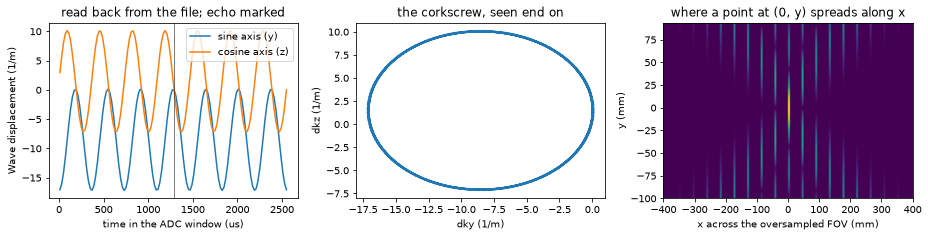

In [3]:
y_pos = (np.arange(NY) - NY // 2) * FOV_M[1] / NY
z_pos = (np.arange(NZ) - NZ // 2) * FOV_M[2] / NZ
x_pos = (np.arange(NX) - NX // 2) * FOV_M[0] / NX


def wave_psf(dk, sign=-1):
    """``(N, NY, NZ)``: ``exp(sign * i 2 pi (dky * y + dkz * z))`` on the reconstruction grid."""
    return np.exp(sign * 2j * np.pi * (dk[1][:, None, None] * y_pos[None, :, None]
                                       + dk[2][:, None, None] * z_pos[None, None, :]))


def fftc(x, axes):
    return np.fft.fftshift(np.fft.fftn(np.fft.ifftshift(x, axes=axes), axes=axes, norm='ortho'),
                           axes=axes)


def ifftc(x, axes):
    return np.fft.fftshift(np.fft.ifftn(np.fft.ifftshift(x, axes=axes), axes=axes, norm='ortho'),
                           axes=axes)


crop = slice(N // 2 - NX // 2, N // 2 + NX // 2)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
t_us = (np.arange(N) + 0.5) * float(nominal['dwell_s']) * 1e6
axes[0].plot(t_us, displacement[1], label='sine axis (y)')
axes[0].plot(t_us, displacement[2], label='cosine axis (z)')
axes[0].axvline(t_us[ECHO], color='k', lw=0.5)
axes[0].set(xlabel='time in the ADC window (us)', ylabel='Wave displacement (1/m)',
            title='read back from the file; echo marked')
axes[0].legend()
axes[1].plot(displacement[1], displacement[2])
axes[1].set(xlabel='dky (1/m)', ylabel='dkz (1/m)', title='the corkscrew, seen end on')
point_spread = np.abs(ifftc(wave_psf(displacement), (0,)))
axes[2].imshow(point_spread[:, :, NZ // 2].T, aspect='auto', origin='lower',
               extent=[-OS * FOV_M[0] / 2e-3, OS * FOV_M[0] / 2e-3, y_pos[0] * 1e3, y_pos[-1] * 1e3])
axes[2].set(xlabel='x across the oversampled FOV (mm)', ylabel='y (mm)',
            title='where a point at (0, y) spreads along x')
plt.tight_layout()

**Sign convention.** Suppose a simulator's data are `sum rho exp(sigma i 2 pi k . r)` for a sign
`sigma` it chooses. Taking the inverse FFT over the encoded y and z leaves
`exp(-i 2 pi dk(n) . r)` on the reconstruction grid **for either sigma**, because the sigma
that mirrors the image also mirrors the grid. So the PSF's sign is fixed by the
reconstruction's FFT convention. The opposite sign is kept below as a negative control.

## 1. An exact-encoding control: an object on the reconstruction grid

In [4]:
def dft(k, positions, weights, chunk=2048):
    """``sum_v w_v exp(-i 2 pi k(n) . r_v)`` at every sample: the encoding and nothing else."""
    out = np.empty(k.shape[1], complex)
    for start in range(0, k.shape[1], chunk):
        out[start:start + chunk] = np.exp(
            -2j * np.pi * (k[:, start:start + chunk].T @ positions.T)) @ weights
    return out


def cube(signal, table):
    """Place ``(lines * N, ...)`` samples into an ``(N, NY, NZ, ...)`` k-space cube."""
    rows = signal.reshape(len(table), N, *signal.shape[1:])
    out = np.zeros((N, NY, NZ, *signal.shape[1:]), complex)
    for r, (line, part) in enumerate(table):
        out[:, line, part] = rows[r]
    return out


def direct(signal, table, dk=None, sign=-1):
    """Full-sampling reconstruction: y/z inverse FFT, undo the Wave PSF, x inverse FFT, crop."""
    hybrid = ifftc(cube(signal, table), (1, 2))
    if dk is not None:
        psf = np.conj(wave_psf(dk, sign))
        hybrid = hybrid * (psf if hybrid.ndim == 3 else psf[..., None])
    return ifftc(hybrid, (0,))[crop]


def relative_error(image, truth):
    """After one complex scale (the FFT normalisation), ``|| a - b || / || b ||``."""
    a, b = image.reshape(-1), truth.reshape(-1)
    return float(np.linalg.norm(np.vdot(a, b) / np.vdot(a, a) * a - b) / np.linalg.norm(b))


k_plain_file, _ = read_back(FILES[('plain', 'full')])
grid = np.stack(np.meshgrid(x_pos, y_pos, z_pos, indexing='ij'), -1).reshape(-1, 3)
rng = np.random.default_rng(0)
rho = rng.standard_normal(grid.shape[0]) + 1j * rng.standard_normal(grid.shape[0])
truth = rho.reshape(NX, NY, NZ)
exact = {'plain': dft(k_plain_file, grid, rho), 'wave': dft(k_file, grid, rho)}

seq_fork = pp.Sequence()
seq_fork.read(str(FILES[('wave', 'full')]))
k_fork = np.asarray(seq_fork.calculate_kspace()[0])        # the fork's sampled-then-interpolated k
fork_displacement = (k_fork.reshape(3, len(TABLES['full']), N)
                     - encoding_target(TABLES['full'])[:, :, None]).mean(axis=1)

controls = {
    'no Wave, FFT': direct(exact['plain'], TABLES['full']),
    'Wave, PSF from the file': direct(exact['wave'], TABLES['full'], displacement),
    "Wave, PSF from 01's k_per_m()": direct(exact['wave'], TABLES['full'], nominal['wave_k_per_m']),
    'Wave, PSF from calculate_kspace()': direct(exact['wave'], TABLES['full'], fork_displacement),
    'Wave, PSF with the other sign': direct(exact['wave'], TABLES['full'], displacement, sign=+1),
    'Wave, no PSF': direct(exact['wave'], TABLES['full']),
}
for name, image in controls.items():
    print(f'{name:36s} relative error {relative_error(image, truth):.1e}')
print(f'(calculate_kspace() differs from the exact trajectory by up to '
      f'{np.abs(fork_displacement - displacement).max():.2f} 1/m)')
assert relative_error(controls['Wave, PSF from the file'], truth) < 1e-4
assert relative_error(controls["Wave, PSF from 01's k_per_m()"], truth) < 1e-4
assert relative_error(controls['Wave, PSF with the other sign'], truth) > 0.5

no Wave, FFT                         relative error 1.6e-05
Wave, PSF from the file              relative error 1.8e-05
Wave, PSF from 01's k_per_m()        relative error 2.0e-05
Wave, PSF from calculate_kspace()    relative error 2.0e-01
Wave, PSF with the other sign        relative error 9.9e-01
Wave, no PSF                         relative error 9.8e-01
(calculate_kspace() differs from the exact trajectory by up to 0.89 1/m)


The Wave reconstruction is exact to the file's six-digit amplitude rounding, whether the PSF is
taken from the file or from the module. Either wrong sign or no PSF destroys it.

The `calculate_kspace()` row is a trap specific to this environment. In the pinned PyPulseq
fork that function samples gradients on the raster and interpolates, which places k half a
gradient raster late. As a PSF that costs the reconstruction its accuracy. `calculate_kspacePP`
and `k_per_m()` are exact.

## 2. Bloch simulation of the written files

MRzero reads each file itself. The phantom has 3 mm in-plane voxels and 7.5 mm through-slab
voxels, finer than the 6.25 mm / 15 mm image grid. That way the Wave's k excursions beyond the
encoded range are not cut off by the phantom's own resolution. The four simulations take about
twelve minutes.

`01` plays 200 dummies, which brings the spoiled signal within about 1 % of steady state. That
matters more for Wave than for a plain 3D GRE. A transient weights k-space line by line, and
that weighting does not commute with the Wave PSF. With the 8 dummies `gre_3d` uses, the Wave
reconstruction below came out 0.19 from the no-Wave one, rather than 0.06.

In [5]:
obj = ph.built_3d(matrix=(64, 64, 16), z_extent_mm=float(nominal['fov_mm'][2]), n_coils=8)


def simulate(path, *, states=200):
    seq = mr0.Sequence.import_file(str(path))
    with contextlib.redirect_stdout(io.StringIO()):         # MRzero's own timing printout
        graph = mr0.compute_graph(seq, obj, max_state_count=states, min_state_mag=1e-4)
    signal = mr0.execute_graph(graph, seq, obj, min_emitted_signal=1e-4, min_latent_signal=1e-5,
                               print_progress=False)
    return np.asarray(signal.detach().cpu().numpy())


signals = {}
for key, path in FILES.items():
    started = time.time()
    signals[key] = simulate(path)
    print(f'{key[0]:5s} {key[1]:5s} {signals[key].shape}  {time.time() - started:.0f} s')

>>>> Rust - compute_graph(...) >>>


Converting Python -> Rust: 0.001590542 s
Compute Graph
Computing Graph: 0.17093855 s
Analyze Graph
Analyzing Graph: 0.0041845 s
Converting Rust -> Python: 0.072545454 s
<<<< Rust <<<<


wave  full  (32768, 8)  286 s


>>>> Rust - compute_graph(...) >>>
Converting Python -> Rust: 0.001406958 s
Compute Graph
Computing Graph: 0.071659416 s
Analyze Graph
Analyzing Graph: 0.001846416 s
Converting Rust -> Python: 0.031968 s
<<<< Rust <<<<


wave  caipi (8192, 8)  155 s


>>>> Rust - compute_graph(...) >>>
Converting Python -> Rust: 0.001599041 s
Compute Graph


Computing Graph: 0.112459 s
Analyze Graph
Analyzing Graph: 0.003675375 s
Converting Rust -> Python: 0.06671796 s
<<<< Rust <<<<


plain full  (32768, 8)  162 s
>>>> Rust - compute_graph(...) >>>


Converting Python -> Rust: 0.000600125 s
Compute Graph
Computing Graph: 0.03434604 s
Analyze Graph
Analyzing Graph: 0.001422083 s
Converting Rust -> Python: 0.026065 s
<<<< Rust <<<<


plain caipi (8192, 8)  43 s


### Fully sampled: Wave against no-Wave

no Wave                              NRMSE against no-Wave 0.000
Wave, PSF from the file              NRMSE against no-Wave 0.061
Wave, PSF from calculate_kspace()    NRMSE against no-Wave 0.093
Wave, no PSF                         NRMSE against no-Wave 0.441


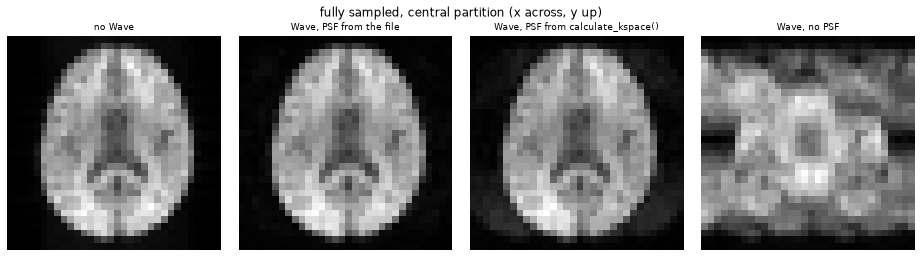

In [6]:
def rss(image):
    return np.sqrt(np.sum(np.abs(image) ** 2, axis=-1))


reference = rss(direct(signals[('plain', 'full')], TABLES['full']))


def nrmse(image, ref=reference, mask=None):
    """Magnitude NRMSE inside the object, after one real scale."""
    mask = ref > 0.1 * ref.max() if mask is None else mask
    a = np.abs(image) * np.sum(np.abs(image) * ref * mask) / np.sum(np.abs(image) ** 2 * mask)
    return float(np.sqrt(np.sum(((a - ref) * mask) ** 2) / np.sum((ref * mask) ** 2)))


full = {
    'no Wave': reference,
    'Wave, PSF from the file': rss(direct(signals[('wave', 'full')], TABLES['full'], displacement)),
    'Wave, PSF from calculate_kspace()': rss(direct(signals[('wave', 'full')], TABLES['full'],
                                                    fork_displacement)),
    'Wave, no PSF': rss(direct(signals[('wave', 'full')], TABLES['full'])),
}
for name, image in full.items():
    print(f'{name:36s} NRMSE against no-Wave {nrmse(image):.3f}')

fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
for ax, (name, image) in zip(axes, full.items()):
    ax.imshow(image[:, :, NZ // 2].T, cmap='gray', origin='lower')
    ax.set_title(name, fontsize=9)
    ax.axis('off')
plt.suptitle('fully sampled, central partition (x across, y up)')
plt.tight_layout()

With the PSF taken from the file, the Wave acquisition reconstructs the same image as the
no-Wave one, to the residual printed above. Without a PSF the voxels stay spread along x. The
trajectory half a raster late spreads them less, but visibly.

**What the residual is.** The reconstruction applies the PSF at voxel centres, which is the
standard Wave-CAIPI model. Within one 6.25 mm voxel the Wave phase varies by up to
`max|dky| * dy`, about 0.1 cycle here. Content finer than the image grid, which this phantom
has, therefore does not reconstruct exactly. The same exact-encoding signal model as above,
applied to **the same phantom** with no relaxation and one uniform coil, shows a residual of the
same size without the simulator.

In [7]:
fine = ph.built_3d(matrix=(64, 64, 16), z_extent_mm=float(nominal['fov_mm'][2]), n_coils=0)
positions, density = fine.voxel_pos.numpy().astype(float), fine.PD.numpy().astype(complex)
fine_plain = np.abs(direct(dft(k_plain_file, positions, density), TABLES['full']))
fine_wave = np.abs(direct(dft(k_file, positions, density), TABLES['full'], displacement))
print(f'exact encoding of the same phantom, no relaxation: Wave+PSF NRMSE against no-Wave '
      f'{nrmse(fine_wave, fine_plain):.3f}')

exact encoding of the same phantom, no relaxation: Wave+PSF NRMSE against no-Wave 0.077


## 3. Accelerated: R = 2 x 2 CAIPI, with and without the Wave

CG-SENSE on the hybrid-space forward model:

```text
image -> coil sensitivity -> zero-pad to the oversampled FOV -> FFT along x
      -> x Wave PSF (Wave files only) -> FFT along y, z -> the sampled lines
```

The coil maps come from the fully sampled no-Wave acquisition (a calibration scan), and the same
maps serve every reconstruction. Without noise, both encodings are nearly invertible at this
size. What Wave is for is **noise amplification**, so that is measured by pseudo-replica:
complex noise added to the k-space data, and the voxel-wise standard deviation of the R = 4
reconstruction divided by `sqrt(R)` times that of the fully sampled one under the same
encoding.

In [8]:
coil_images = direct(signals[('plain', 'full')], TABLES['full'])
coil_rss = rss(coil_images)
support = coil_rss > 0.08 * coil_rss.max()
maps = np.where(support[..., None], coil_images / np.maximum(coil_rss, 1e-12)[..., None], 0)
COILS = maps.shape[-1]


class Encoding:
    """The forward model above, for one table, with or without a Wave PSF."""

    def __init__(self, table, psf):
        self.lines = np.array([line for line, _ in table])
        self.parts = np.array([part for _, part in table])
        self.psf = psf

    def forward(self, u):
        padded = np.zeros((N, NY, NZ, COILS), complex)
        padded[crop] = maps * u[..., None]
        hybrid = fftc(padded, (0,))
        if self.psf is not None:
            hybrid = hybrid * self.psf[..., None]
        return fftc(hybrid, (1, 2))[:, self.lines, self.parts, :]

    def adjoint(self, data):
        k = np.zeros((N, NY, NZ, COILS), complex)
        np.add.at(k, (slice(None), self.lines, self.parts), data)
        hybrid = ifftc(k, (1, 2))
        if self.psf is not None:
            hybrid = hybrid * np.conj(self.psf)[..., None]
        return np.sum(np.conj(maps) * ifftc(hybrid, (0,))[crop], axis=-1)


def cg_sense(encoding, data, iterations=30):
    b = encoding.adjoint(data)
    x, r = np.zeros_like(b), b.copy()
    p, rr = r.copy(), np.vdot(r, r)
    for _ in range(iterations):
        if abs(rr) < 1e-20 * abs(np.vdot(b, b)):          # converged exactly
            break
        ap = encoding.adjoint(encoding.forward(p)) * support
        alpha = rr / np.vdot(p, ap)
        x, r = x + alpha * p, r - alpha * ap
        rr, rr_old = np.vdot(r, r), rr
        p = r + (rr / rr_old) * p
    return x * support


psf = wave_psf(displacement)
encodings = {(name, size): Encoding(TABLES[size], psf if name == 'wave' else None)
             for name in ('wave', 'plain') for size in ('full', 'caipi')}
data = {key: signals[key].reshape(len(TABLES[key[1]]), N, COILS).transpose(1, 0, 2)
        for key in encodings}
clean = {key: cg_sense(encodings[key], data[key]) for key in encodings}
for key, image in clean.items():
    print(f'{key[0]:5s} {key[1]:5s} NRMSE against the same encoding fully sampled '
          f'{nrmse(image, np.abs(clean[(key[0], "full")])):.3f}')

wave  full  NRMSE against the same encoding fully sampled 0.000
wave  caipi NRMSE against the same encoding fully sampled 0.040
plain full  NRMSE against the same encoding fully sampled 0.000
plain caipi NRMSE against the same encoding fully sampled 0.060


plain g-factor at R = 4: mean 2.04, 95th percentile 3.61, max 6.24
wave  g-factor at R = 4: mean 1.11, 95th percentile 1.55, max 2.64


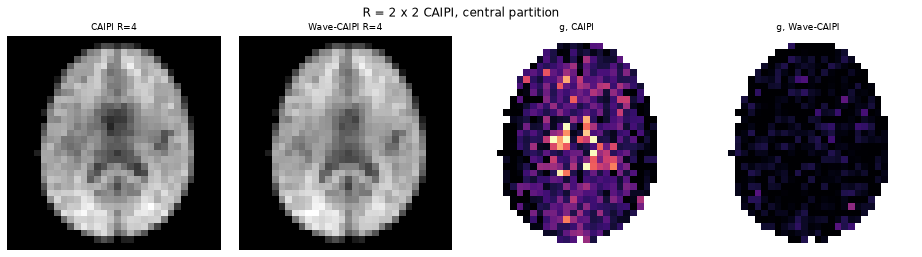

In [9]:
REPLICAS = 12
sigma = 0.03 * np.abs(data[('plain', 'full')]).mean()
rng = np.random.default_rng(1)
noise_std = {}
for key, encoding in encodings.items():
    replicas = []
    for _ in range(REPLICAS):
        noise = sigma * (rng.standard_normal(data[key].shape)
                         + 1j * rng.standard_normal(data[key].shape)) / np.sqrt(2)
        replicas.append(cg_sense(encoding, data[key] + noise) - clean[key])
    noise_std[key] = np.std(np.stack(replicas), axis=0)
R = len(TABLES['full']) / len(TABLES['caipi'])
with np.errstate(invalid='ignore', divide='ignore'):        # zero outside the support
    g = {name: np.where(support, noise_std[(name, 'caipi')]
                        / (noise_std[(name, 'full')] * np.sqrt(R)), np.nan)
         for name in ('plain', 'wave')}
for name, gmap in g.items():
    values = gmap[support]
    print(f'{name:5s} g-factor at R = {R:.0f}: mean {values.mean():.2f}, '
          f'95th percentile {np.percentile(values, 95):.2f}, max {values.max():.2f}')

fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
panels = [('CAIPI R=4', np.abs(clean[('plain', 'caipi')])),
          ('Wave-CAIPI R=4', np.abs(clean[('wave', 'caipi')])),
          ('g, CAIPI', g['plain']), ('g, Wave-CAIPI', g['wave'])]
top = max(np.percentile(g['plain'][support], 99), np.percentile(g['wave'][support], 99))
for ax, (name, image) in zip(axes, panels):
    shown = image[:, :, NZ // 2].T
    kwargs = dict(vmin=1.0, vmax=top, cmap='magma') if name.startswith('g') else dict(cmap='gray')
    ax.imshow(shown, origin='lower', **kwargs)
    ax.set_title(name, fontsize=9)
    ax.axis('off')
plt.suptitle('R = 2 x 2 CAIPI, central partition')
plt.tight_layout()

In [10]:
assert relative_error(controls['Wave, PSF from the file'], truth) < 1e-4
assert nrmse(full['Wave, PSF from the file']) < 0.1
assert nrmse(full['Wave, no PSF']) > 3 * nrmse(full['Wave, PSF from the file'])
assert g['wave'][support].mean() < g['plain'][support].mean()

## What was shown, and what was not

**Demonstrated, in simulation, from the written files:**

- **The trajectory the files play is the one `WaveReadout` reports.** The read-back k minus each
  line's encoding target is the same in every repetition and equals `k_per_m()`. MRzero's own
  reading of the file agrees with PyPulseq's.
- **The Wave encoding is exact under its own model.** For an object on the reconstruction grid,
  the PSF built from the file inverts the Wave to the file's rounding. The opposite sign, or no
  PSF, does not. A trajectory half a gradient raster off, which is what `calculate_kspace()`
  returns in the pinned fork, costs about a fifth of the image.
- **A Bloch simulation of the written Wave file reconstructs the same volume as the no-Wave
  file** once the PSF from the file is applied. The residual is about the size the voxel-grid PSF
  model leaves for a phantom finer than the image. Without the PSF the image is spread.
- **Wave-CAIPI's conditioning benefit follows from the emitted Wave.** At R = 2 x 2 its
  pseudo-replica g-factor is lower than the same acquisition's without the Wave. The two files
  differ only in the readout module.

**Modelling assumptions:**

- the voxel-grid Wave PSF of the standard Wave-CAIPI model;
- coil maps from a fully sampled no-Wave calibration, shared by every reconstruction;
- white noise, equal per sample, at one level;
- MRzero's physics: the phantom's B0 map, relaxation, sinc voxels, eight synthetic coils, and
  **ideal gradients** (no delays, eddy currents or gradient impulse response);
- 200 dummies to a near steady state.

**Not established here:**

- **how a scanner plays these gradients.** Gradient delays and eddy currents are exactly what a
  measured PSF calibration corrects, and this notebook uses only the nominal one;
- g-factors at clinical matrices and coil arrays. This is a 32 x 32 x 8 simulation-size
  protocol: 3.5 mT/m, 7 cycles, a 2.56 ms window;
- PNS, acoustics, and image quality on a scanner.